# The machine learning lifecycle and linear regression

After this block you can place a machine learning project in its lifecycle, from problem definition to monitoring, and name the target, the metric and the baseline before any model is fitted. You can split data into training and test sets, fit, interpret and diagnose a simple and a multiple linear regression, report its error in euros against a baseline, and recognise underfitting and overfitting by comparing training and test error.

The running question: **what drives the nightly price of a Berlin Airbnb listing?** A host who prices a new flat needs the answer in euros.

## Overview

| Section | What it covers |
|---|---|
| The machine learning lifecycle | the ten stages and the loops back, problem definition: target, metric, baseline |
| Supervised learning: features, target, training, prediction | observations, features, target, model and parameters, the log price and the distance feature, a line drawn by hand, `fit` and `predict` |
| Training and test sets | generalisation, `train_test_split`, the median-price baseline |
| Simple and multiple linear regression | least squares by hand and as a search, statsmodels, the coefficient table, confidence and prediction intervals, dummy variables, coefficients and scale, interactions, residuals, leverage and collinearity, nested models |
| Regression metrics | MAE, MSE, RMSE, R², training and test error, the mean as a model, median and percentage errors, prediction-error plots and the log target |
| Worked example | four price models step by step against the baseline, the most mispriced listings |
| Underfitting and overfitting | model complexity, polynomial features, training and test error by degree, cross-validated error, splines, bins and trees, the bias–variance trade-off |
| Check your understanding, Exercises, Debrief | five questions, seven exercises in pairs, what to compare afterwards |

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

All imports of the block in one cell. `statsmodels.formula.api` (imported as `smf`) fits regressions from a formula such as `"log_price ~ accommodates"`; scikit-learn provides the split, the metrics and the polynomial models.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (PredictionErrorDisplay, mean_absolute_error,
                             mean_absolute_percentage_error, mean_squared_error,
                             median_absolute_error, r2_score, root_mean_squared_error)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (KBinsDiscretizer, PolynomialFeatures, SplineTransformer,
                                   StandardScaler)
from sklearn.tree import DecisionTreeRegressor
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

## The machine learning lifecycle

A machine learning project is much more than fitting a model, in the same way that building a house is more than laying bricks. The **lifecycle** lists the stages from a business question to a model that runs and is looked after:

| Stage | Question | Course sessions |
|---|---|---|
| 01 Problem definition | What do we predict, for whom, measured how? What is the baseline? | S6 |
| 02 Data collection | Which data exist, and may we use them? | S3 |
| 03 Cleaning | Are the data correct, complete, consistent? | S4 |
| 04 Exploratory analysis | What is in the data; which relationships are real? | S5 |
| 05 Features | Which inputs does the model get? | S9 |
| 06 Model selection | Which family of models fits the problem? | S7, S8, S10 |
| 07 Training | Fit the parameters on training data. | S6 onwards |
| 08 Evaluation and tuning | How good is it on new data; which settings are best? | S6, S7, S8 |
| 09 Deployment | Make predictions available to users or systems. | S16 |
| 10 Monitoring and maintenance | Does it still work as the world changes? | S16 |

```mermaid
flowchart LR
    P["01 Problem"] --> C["02 Data"] --> D["03 Cleaning"] --> E["04 EDA"] --> F["05 Features"]
    F --> S["06 Model<br/>selection"] --> T["07 Training"] --> V["08 Evaluation"] --> Y["09 Deployment"] --> M["10 Monitoring"]
    V -.->|"not good enough"| F
    V -.->|"wrong target or metric"| P
    M -.->|"the world changed"| C
```

The arrows back matter most: projects loop. A failed evaluation sends you back to features or data; monitoring that detects a change sends you back to data collection and retraining. The classic process model of this kind is CRISP-DM (Chapman et al., 2000), with six phases from business understanding to deployment; most lifecycle diagrams descend from it. Sculley et al. (2015) add the warning that in real systems the model code is a small part, surrounded by data collection, feature extraction, serving and monitoring.

Sessions 3–5 already covered stages 02–04 on the Berlin listings: SQL on the listings (Session 3), cleaning (Session 4) and exploration (Session 5). Today starts at stage 01 and goes to stage 08.

### Problem definition: target, metric and baseline

**Problem definition** is the first stage of the lifecycle. It fixes three things before any model is fitted:

- the **target**: what is predicted (here the price per night);
- the **metric**: how success is measured (here the mean absolute error in euros on listings the model has not seen);
- the **baseline**: the simplest prediction a model must beat (here the median price, the same for every listing).

Next we load the listings. As in Sessions 4 and 5 we keep listings with a price and a minimum stay below 28 nights, because the price field of medium-term rentals is not comparable. `df.loc[mask]` keeps the rows where the Boolean mask is `True`.

In [3]:
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings.loc[listings["price"].notna() & listings["minimum_nights"].lt(28)].copy()
print(len(listings), "listings,", len(short), "short-stay listings with a price")
short[["price", "accommodates", "room_type", "district"]].head(3)

10221 listings, 5302 short-stay listings with a price


,price,accommodates,room_type,district
0,160.71,2,Entire home/apt,Pankow
1,193.33,7,Entire home/apt,Pankow
4,372.67,4,Entire home/apt,Pankow


## Supervised learning: features, target, training, prediction

Supervised learning is learning from worked examples with the answers attached, like practising with past exam papers and their solutions.

- An **observation** is one row: one listing.
- The **features** (inputs, X) are what we know about it: number of guests, room type, location.
- The **target** (output, y) is what we want to predict: the nightly price.
- A **model** is a family of prediction rules with free numbers, its **parameters**. **Training** (fitting) chooses the parameters from rows whose target is known. **Prediction** applies the fitted model to rows whose target is unknown, such as a host's new flat.

It is **regression** when the target is a number and **classification** when it is a category (block 2). Statisticians say predictor and response for feature and target, and estimate for a learned parameter; the ideas are the same.

### The target and a new feature: log price and distance

Prices are right-skewed (Session 5): a few listings cost thousands. We model the **log price**, on which a coefficient reads as a percentage difference. We also add one feature, the distance to Alexanderplatz in kilometres.

Next we create the target and the distance feature. `np.log` takes the natural logarithm; `np.hypot(a, b)` is √(a² + b²), and one degree of latitude is about 111.2 km.

In [4]:
short["log_price"] = np.log(short["price"])
short["km_to_centre"] = 111.2 * np.hypot(
    short["latitude"] - 52.5219,                                   # Alexanderplatz
    (short["longitude"] - 13.4132) * np.cos(np.radians(52.52)),
)
short[["price", "log_price", "km_to_centre"]].describe().round(2)

,price,log_price,km_to_centre
count,5302.00,5302.00,5302.00
mean,195.60,5.07,5.25
std,235.19,0.60,4.02
min,9.03,2.20,0.22
25%,107.50,4.68,2.56
50%,157.50,5.06,4.10
75%,230.50,5.44,6.64
max,10025.00,9.21,25.16


### A line drawn by hand

*Adapted from [Linear regression without scikit-learn](extras/01-linear-regression-without-sklearn.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

Before any library, a linear model is just a function with two numbers: price = slope × guests + intercept. The **slope** (also called the weight or coefficient) has a unit, here euros per guest: a slope of 30 means each additional guest adds €30 to the prediction. The **intercept** is the prediction at zero guests, a purely mathematical point because no listing has zero guests. A negative slope would mean larger listings are cheaper.

Next we write the model as a Python function and draw three hand-chosen lines over the listings with a price below €600. `np.linspace(a, b, n)` makes `n` evenly spaced values; `ax.plot` draws a line over the scatter.

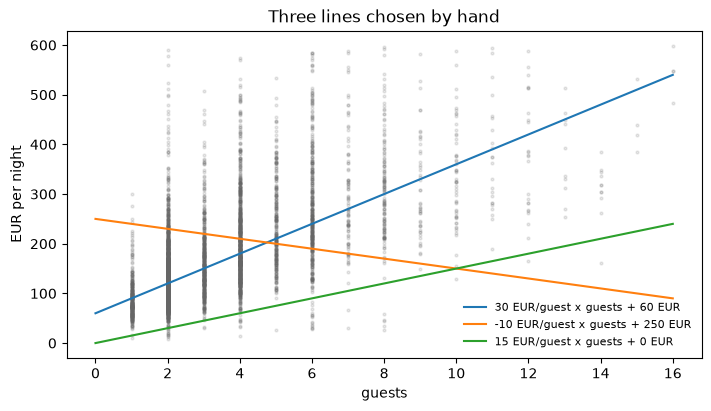

In [5]:
def linear_price(guests, slope, intercept):
    # A linear model of the form price = slope * guests + intercept.
    return slope * guests + intercept

plain = short.loc[short["price"] < 600]
guests_range = np.linspace(0, 16, 50)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.scatter(plain["accommodates"], plain["price"], s=4, alpha=0.15, color="0.4")
for slope, intercept in [(30, 60), (-10, 250), (15, 0)]:
    ax.plot(guests_range, linear_price(guests_range, slope, intercept),
            label=f"{slope} EUR/guest x guests + {intercept} EUR")
ax.set(xlabel="guests", ylabel="EUR per night", title="Three lines chosen by hand")
ax.legend(frameon=False, fontsize=8)
plt.show()

The negative slope is clearly wrong; the line through the origin is too flat. Choosing the best line is the job of training, which the section on linear regression does with least squares.

### Features and target in code: `fit` and `predict`

Next, the vocabulary in code. `X` is a 2-D table with one column per feature (`short[["accommodates"]]`, double brackets); `y` is a 1-D column (`short["log_price"]`). `LinearRegression().fit(X, y)` trains, `.predict(X)` predicts.

**Predict before running:** the model learns one number per guest. Will a listing for four guests get a higher or a lower predicted price than one for two?

In [6]:
X = short[["accommodates"]]            # features: 2-D
y = short["log_price"]                 # target: 1-D
model = LinearRegression().fit(X, y)   # training
new_flats = pd.DataFrame({"accommodates": [2, 4]})
print(np.exp(model.predict(new_flats)).round(0))   # prediction, back in euros

[125. 171.]


> **Note.** A feature must be known at the moment of prediction. `estimated_revenue_l365d` is computed by Inside Airbnb from the price itself, and a new flat has no reviews yet. Using either to predict the price would make the model look better than it can be in use (leakage, Sessions 7 and 9).

## Training and test sets

A model is useful if it predicts **new** rows well. A student who has seen the exam questions in advance scores well without having learned anything; a model scored on its own training rows does the same. So we hold back part of the labelled data as a **test set**, fit only on the **training set**, and score the final model once on the test set. The test score estimates the **generalisation** performance: how well the model does on listings it has never seen.

`train_test_split` shuffles the rows and splits them, here 80 % / 20 %. A fixed `random_state` makes the split the same every time. When the future is predicted from the past, split by time instead (Session 12); when one host has many similar flats, keep each host on one side (grouped splits, Session 7).

Next we split the listings. `train_test_split(df, test_size=0.2, random_state=42)` returns two DataFrames.

In [7]:
train, test = train_test_split(short, test_size=0.2, random_state=42)
print(len(train), "training listings,", len(test), "test listings")
print("median price train / test:", train["price"].median(), "/", test["price"].median())

4241 training listings, 1061 test listings
median price train / test: 158.0 / 154.0


Next, the baseline of the problem definition: predict the median training price for every test listing and measure the mean absolute error (MAE), the average distance between prediction and true price in euros. `np.full(n, value)` makes an array of `n` copies.

In [8]:
baseline = train["price"].median()
baseline_mae = mean_absolute_error(test["price"], np.full(len(test), baseline))
print(f"baseline: {baseline:.1f} EUR for every listing, test MAE {baseline_mae:.1f} EUR")

baseline: 158.0 EUR for every listing, test MAE 87.1 EUR


Every model in this block has to beat this number.

> **Note.** Touch the test set once. If you try ten models and keep the one with the best test score, that score is no longer an honest estimate. Session 7 chooses models with cross-validation on the training data.

## Simple and multiple linear regression

### Simple linear regression and least squares

**Simple linear regression** draws a straight line through a cloud of points: ŷ = b₀ + b₁·x. The **intercept** b₀ is the prediction at x = 0; the **slope** b₁ is the change in the prediction per one-unit increase of x. The **residual** of a row is y − ŷ, its vertical distance to the line.

**Least squares** chooses the line with the smallest sum of squared residuals. For one feature there is a closed formula: the slope is the covariance of x and y divided by the variance of x, and the line passes through the point of means (x̄, ȳ). Squaring makes all residuals positive and punishes large misses more than small ones; block 2 returns to this choice.

Worked example: for the points (1, 2), (2, 3), (3, 5), x̄ = 2 and ȳ = 10/3. The slope is [(−1)(−4/3) + 0 + (1)(5/3)] / [1 + 0 + 1] = 3 / 2 = 1.5, and the intercept 10/3 − 1.5 · 2 ≈ 0.33.

Next we check the hand calculation with NumPy. Arithmetic on arrays works element by element, so `(x - x.mean()) * (y - y.mean())` gives one product per point.

In [9]:
x_pts = np.array([1, 2, 3])
y_pts = np.array([2, 3, 5])
b1 = ((x_pts - x_pts.mean()) * (y_pts - y_pts.mean())).sum() / ((x_pts - x_pts.mean()) ** 2).sum()
b0 = y_pts.mean() - b1 * x_pts.mean()
print(round(b0, 2), round(b1, 2))

0.33 1.5


### Least squares as a search

*Adapted from [Linear regression using scikit-learn](extras/02-linear-regression-in-sklearn.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

One way to find the best line is brute force: try many slopes, compute the mean squared error (MSE) of each, keep the smallest. Least squares has a closed-form solution, so scikit-learn and statsmodels solve an equation instead of searching, but the search shows what "best" means. Any other slope gives a higher training MSE.

Next we fix the intercept at the value that keeps the line through the point of means and scan 200 slopes for the log price on guests. `np.argmin` returns the position of the smallest value.

best slope by search 0.154, by LinearRegression 0.153, intercept 4.530


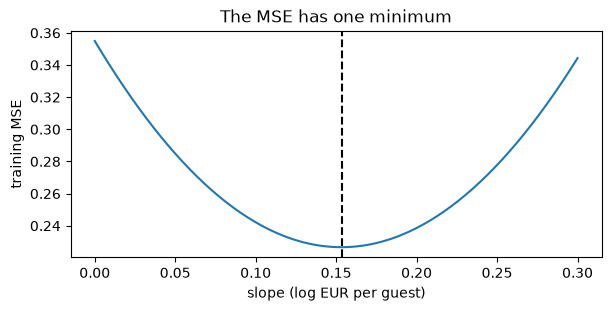

In [10]:
x_g, y_lp = train["accommodates"].to_numpy(), train["log_price"].to_numpy()
slopes = np.linspace(0, 0.3, 200)
mse = [np.mean((y_lp - (y_lp.mean() + s * (x_g - x_g.mean()))) ** 2) for s in slopes]
best = slopes[np.argmin(mse)]
lr = LinearRegression().fit(train[["accommodates"]], train["log_price"])
print(f"best slope by search {best:.3f}, by LinearRegression {lr.coef_[0]:.3f}, intercept {lr.intercept_:.3f}")
fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
ax.plot(slopes, mse)
ax.axvline(best, color="black", ls="--")
ax.set(xlabel="slope (log EUR per guest)", ylabel="training MSE", title="The MSE has one minimum")
plt.show()

`LinearRegression` stores what it learned in `coef_` (one slope per feature) and `intercept_`; the trailing underscore marks attributes that exist only after fitting.

### Simple regression in statsmodels

Next, the simple regression of log price on the number of guests with statsmodels, which gives the statistical view. `smf.ols("y ~ x", data=df).fit()` fits by least squares and adds the intercept itself; `.params` holds the coefficients and `.rsquared` the share of variance explained on the training rows.

In [11]:
simple = smf.ols("log_price ~ accommodates", data=train).fit()
print(simple.params.round(3))
print("R2:", round(simple.rsquared, 3))

Intercept       4.530
accommodates    0.153
dtype: float64
R2: 0.361


On the log scale, a coefficient b means a price that is e^b − 1 higher in per cent. Here e^0.153 − 1 ≈ 17 % per additional guest.

### The statsmodels coefficient table

*Adapted from [ISLP Lab 3, Linear Regression](extras/03-islp-linear-regression-lab.ipynb) (ISLP labs, BSD-2-Clause).*

Each coefficient is an estimate from a sample, so statsmodels reports its uncertainty:

- **std err**: how much the estimate would vary from sample to sample;
- **t**: the coefficient divided by its standard error;
- **P>|t|**: the p-value of the test "the true coefficient is zero" (Session 5);
- **[0.025, 0.975]**: the 95 % confidence interval.

`.summary()` prints the full report; `.summary().tables[1]` is just the coefficient table.

In [12]:
simple.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,4.5298,0.013,340.325,0.000,4.504,4.556
accommodates,0.1533,0.003,48.981,0.000,0.147,0.159


### Confidence and prediction intervals

*Adapted from [ISLP Lab 3](extras/03-islp-linear-regression-lab.ipynb) (ISLP labs, BSD-2-Clause).*

A **confidence interval** for a prediction says where the *average* log price of all listings with, say, four guests lies. A **prediction interval** says where the price of *one* new listing with four guests lies; it also contains the scatter of single listings around the line, so it is much wider. A host asking "what could my flat fetch?" needs the prediction interval.

Next we ask for both at 2, 4 and 6 guests. `.get_prediction(new_df).summary_frame(alpha=0.05)` returns the mean prediction with `mean_ci_*` (confidence) and `obs_ci_*` (prediction) bounds; `np.exp` turns them into euros.

In [13]:
new_df = pd.DataFrame({"accommodates": [2, 4, 6]})
frame = simple.get_prediction(new_df).summary_frame(alpha=0.05)
np.exp(frame[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]]).round(0)

,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,126.0,124.0,128.0,50.0,321.0
1,171.0,169.0,174.0,67.0,436.0
2,233.0,228.0,237.0,91.0,592.0


The typical price of a four-guest listing is pinned down to a few euros, but a single four-guest listing can plausibly cost anywhere in a range several times wider. Guests alone leave most of the price unexplained.

### Multiple linear regression

**Multiple linear regression** adds features: ŷ = b₀ + b₁x₁ + b₂x₂ + … Each coefficient is now the expected difference in y per unit of its feature **with the other features held fixed**.

#### Dummy variables for categories

A category such as room type enters as 0/1 **dummy** columns, one per category except a **reference** category against which the others are compared. This 0/1 coding is also called **one-hot encoding**.

Next we look at the dummy columns for room type. `pd.get_dummies(series, drop_first=True, dtype=int)` creates one 0/1 column per category and drops the first category, which becomes the reference.

In [14]:
print(short["room_type"].value_counts())
pd.get_dummies(short["room_type"], drop_first=True, dtype=int).head(4)

room_type
Entire home/apt    3694
Private room       1483
Hotel room           63
Shared room          62
Name: count, dtype: int64


,Hotel room,Private room,Shared room
0,0,0,0
1,0,0,0
4,0,0,0
6,0,0,0


#### Fitting and reading the multiple model

**Predict before running:** larger listings are more often entire homes. When room type joins the model, will the guest coefficient grow or shrink?

Next, the multiple regression. In a formula, `C(room_type)` creates these dummies itself, and `Treatment("Mitte")` makes Mitte the reference district. `np.exp(params) - 1` converts the coefficients into per cent; `.conf_int()` gives 95 % confidence intervals.

In [15]:
multi = smf.ols(
    'log_price ~ accommodates + C(room_type) + km_to_centre + C(district, Treatment("Mitte"))',
    data=train,
).fit()
rows = ["accommodates", "km_to_centre", "C(room_type)[T.Private room]",
        'C(district, Treatment("Mitte"))[T.Neukölln]']
table = pd.DataFrame({"coef": multi.params, "per cent": 100 * (np.exp(multi.params) - 1),
                      "ci low": multi.conf_int()[0], "ci high": multi.conf_int()[1]})
print("R2:", round(multi.rsquared, 3))
table.loc[rows].round(3)

R2: 0.515


,coef,per cent,ci low,ci high
accommodates,0.124,13.172,0.118,0.130
km_to_centre,-0.024,-2.359,-0.030,-0.018
C(room_type)[T.Private room],-0.389,-32.259,-0.420,-0.359
"C(district, Treatment(""Mitte""))[T.Neukölln]",-0.114,-10.761,-0.168,-0.060


Reading the table (reference: an entire home in Mitte):

- each additional guest goes with a price about e^0.124 − 1 ≈ 13 % higher, holding room type, distance and district fixed. Alone it was 17 %, because part of the guest effect was really the room-type effect;
- a private room costs about 32 % less than an entire home for the same number of guests;
- each kilometre from Alexanderplatz goes with about 2 % less;
- a listing in Neukölln costs about 11 % less than a comparable one in Mitte.

R² rises from 0.36 to 0.52: the four features explain about half of the variation in log price.

> **Note.** Coefficients are not causal effects. "Held fixed" means "compared with listings that have the same values in the data", not "if a host added a bed". A coefficient also absorbs the effect of features left out (confounding, Session 5).

### Coefficients and scale: comparing features fairly

*Adapted from [Common pitfalls in the interpretation of coefficients of linear models](extras/04-coefficient-interpretation-pitfalls.ipynb) (scikit-learn gallery, BSD-3-Clause).*

A coefficient has the unit "target per unit of feature": log EUR per guest, log EUR per kilometre. So the raw sizes of coefficients cannot be compared: the guest coefficient is larger than the distance coefficient partly because a guest is a bigger step than a kilometre. Multiplying each coefficient by the standard deviation of its feature puts them on one scale: the change in log price for a typical (one standard deviation) difference in the feature.

The gallery example also separates two kinds of dependence. A **marginal** dependence looks at one feature alone (the simple regression, 17 % per guest); a **conditional** dependence holds the other features fixed (the multiple regression, 13 % per guest). Both are correct answers to different questions.

Next we compute the standardised effects of guests and distance from the multiple model. `train[cols].std()` gives one standard deviation per column.

In [16]:
num = ["accommodates", "km_to_centre"]
effect = pd.DataFrame({"coef": multi.params[num], "feature sd": train[num].std()})
effect["coef x sd"] = effect["coef"] * effect["feature sd"]
effect.round(3)

,coef,feature sd,coef x sd
accommodates,0.124,2.337,0.289
km_to_centre,-0.024,3.965,-0.095


A typical difference in guests (about two) moves the log price several times more than a typical difference in distance (about four kilometres).

### Interactions: does distance matter equally for every room type?

*Adapted from [ISLP Lab 3](extras/03-islp-linear-regression-lab.ipynb) (ISLP labs, BSD-2-Clause).*

The model so far assumes that each kilometre costs the same percentage for entire homes and private rooms. An **interaction** term lets the slope of one feature depend on another. In a formula, `a:b` adds the product term and `a * b` adds both main effects plus the product.

Next we let the distance slope differ by room type. We keep entire homes and private rooms only, so the comparison has one reference and one other group.

In [17]:
two_types = train.loc[train["room_type"].isin(["Entire home/apt", "Private room"])]
inter = smf.ols("log_price ~ accommodates + km_to_centre * C(room_type)", data=two_types).fit()
inter.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,4.8354,0.017,277.283,0.000,4.801,4.870
C(room_type)[T.Private room],-0.3083,0.025,-12.239,0.000,-0.358,-0.259
accommodates,0.1272,0.003,42.509,0.000,0.121,0.133
km_to_centre,-0.0179,0.002,-9.326,0.000,-0.022,-0.014
km_to_centre:C(room_type)[T.Private room],-0.0132,0.004,-3.585,0.000,-0.020,-0.006


The row `km_to_centre:C(room_type)[T.Private room]` is the difference between the distance slope of private rooms and that of entire homes. Here it is −0.013 with a confidence interval from −0.020 to −0.006: entire homes lose about 1.8 % per kilometre, private rooms about 3.1 % (−0.018 − 0.013). A small but real difference.

### Residuals and diagnostics

Regression **diagnostics** are the checks of whether a fitted model is a fair summary of the data. Most of them look at the residuals y − ŷ or at unusual rows.

#### Residual plots

A model is only a good summary if its residuals look like noise. A **residual plot** (residuals against fitted values) should show a band around zero without a pattern. The left panel below shows what that looks like; the right panel shows the residuals of the multiple price model, computed on all listings.

![Two residual plots: a structureless band for a well-specified model, and the residuals of the Berlin price model with long tails on both sides](../figures/residual-plot.png)

The band is centred and even, so the log scale works, but both tails are long: a few asking prices are far above or below anything comparable.

Next we draw the same plot for the training listings ourselves. `.fittedvalues` and `.resid` are stored on every fitted statsmodels result; `ax.axhline(0)` adds the reference line.

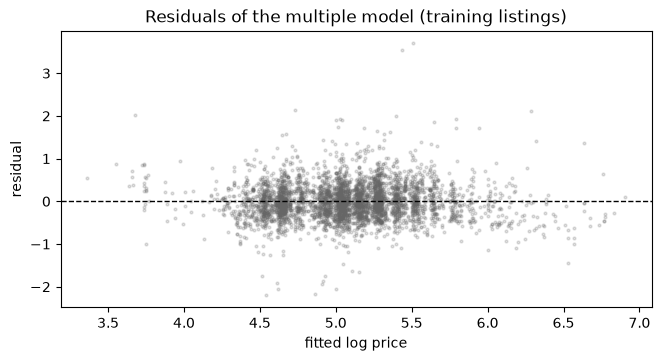

In [18]:
fig, ax = plt.subplots(figsize=(6.5, 3.5), layout="constrained")
ax.scatter(multi.fittedvalues, multi.resid, s=4, alpha=0.2, color="0.4")
ax.axhline(0, color="black", ls="--", lw=1)
ax.set(xlabel="fitted log price", ylabel="residual", title="Residuals of the multiple model (training listings)")
plt.show()

#### Leverage

*Adapted from [ISLP Lab 3](extras/03-islp-linear-regression-lab.ipynb) (ISLP labs, BSD-2-Clause).*

**Leverage** measures how unusual a row's *features* are. A listing for 16 guests far out of town sits at the edge of the feature space and can pull the line towards itself. `get_influence().hat_matrix_diag` gives the leverage of each row; values far above the average (number of parameters / number of rows) deserve a look.

Next we list the three training listings with the highest leverage. `np.argsort(values)[-3:]` gives the positions of the three largest values.

In [19]:
lev = multi.get_influence().hat_matrix_diag
print("average leverage:", round(len(multi.params) / len(train), 4))
top = np.argsort(lev)[-3:]
train.iloc[top][["price", "room_type", "accommodates", "district", "km_to_centre"]].assign(
    leverage=lev[top]).round(3)

average leverage: 0.004


,price,room_type,accommodates,district,km_to_centre,leverage
6630,162.00,Private room,8,Marzahn - Hellersdorf,13.400,0.028
3192,118.00,Hotel room,2,Spandau,14.021,0.034
2756,361.33,Hotel room,3,Spandau,13.620,0.034


The rows with the highest leverage are not the most expensive listings but rare combinations of features: two hotel rooms in Spandau, about 14 km out, and a private room for eight guests in Marzahn-Hellersdorf. Each has seven to nine times the average leverage.

#### Collinearity and the variance inflation factor

*Adapted from [ISLP Lab 3](extras/03-islp-linear-regression-lab.ipynb) (ISLP labs, BSD-2-Clause).*

**Collinearity** means that features carry almost the same information, which makes their separate coefficients unstable. The **variance inflation factor** (VIF) of a feature says how much the variance of its coefficient is inflated by its correlation with the other features. A VIF of 1 means no inflation; values above about 5 to 10 are a warning sign.

Next we compute the VIF of each column of the model matrix. `multi.model.exog` is the matrix statsmodels built from the formula (intercept and dummies included); `variance_inflation_factor(matrix, i)` computes the VIF of column `i`. A list comprehension runs it for every column except the intercept.

In [20]:
exog = multi.model.exog
names = multi.model.exog_names
vif = pd.Series([variance_inflation_factor(exog, i) for i in range(1, exog.shape[1])], index=names[1:])
vif.sort_values(ascending=False).head(5).round(2)

km_to_centre                                                3.23
C(district, Treatment("Mitte"))[T.Treptow - Köpenick]       2.20
C(district, Treatment("Mitte"))[T.Charlottenburg-Wilm.]     1.87
C(district, Treatment("Mitte"))[T.Spandau]                  1.62
C(district, Treatment("Mitte"))[T.Steglitz - Zehlendorf]    1.62
dtype: float64

No VIF comes near 5: distance and district overlap somewhat (distance has the largest VIF), but not enough to make the coefficients unstable.

### Comparing nested models

*Adapted from [ISLP Lab 3](extras/03-islp-linear-regression-lab.ipynb) (ISLP labs, BSD-2-Clause).*

Price may not fall linearly with distance: the centre is a plateau, the outskirts flatten out. Adding the squared distance `I(km_to_centre ** 2)` lets the line bend (`I(...)` tells the formula to compute the expression literally). Two models are **nested** when one is the other plus extra terms. `anova_lm(smaller, larger)` runs an F-test of "the extra terms are not needed".

Next we compare the multiple model with and without the squared distance.

In [21]:
curved = smf.ols(
    'log_price ~ accommodates + C(room_type) + km_to_centre + I(km_to_centre ** 2)'
    ' + C(district, Treatment("Mitte"))', data=train).fit()
anova_lm(multi, curved)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,4224.0,730.595976,0.0,NaN,NaN,NaN
1,4223.0,710.910276,1.0,19.6857,116.938402,6.646545e-27


A tiny p-value (`Pr(>F)`) says the bend is real in the training data. Whether it also helps on new listings is the question of the section on underfitting and overfitting.

> 📖 **Read more:** [extras/01-linear-regression-without-sklearn.ipynb](extras/01-linear-regression-without-sklearn.ipynb) and [extras/02-linear-regression-in-sklearn.ipynb](extras/02-linear-regression-in-sklearn.ipynb) (INRIA scikit-learn MOOC): the same steps on penguin measurements, with grams per millimetre as the slope unit.
>
> 📖 **Read more:** [extras/03-islp-linear-regression-lab.ipynb](extras/03-islp-linear-regression-lab.ipynb) (ISLP labs): the full lab on the Boston and Carseats data with the `ISLP` model-matrix builder.
>
> 📖 **Read more:** [extras/04-coefficient-interpretation-pitfalls.ipynb](extras/04-coefficient-interpretation-pitfalls.ipynb) (scikit-learn gallery): coefficient scale, correlated features, coefficient variability across folds and regularisation on a wage survey.

## Regression metrics

*The subsections from training and test error onwards are adapted from [Regression metrics](extras/05-regression-metrics.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0), with the Ames house prices replaced by the Berlin listings.*

### MAE, MSE, RMSE and R²

A **metric** is the number that says how good the predictions are. With yᵢ the true values and ŷᵢ the predictions:

- **MAE** (mean absolute error): the average size of the error, in euros. A host can read it directly.
- **MSE** (mean squared error): the average squared error, the quantity least squares minimises. Its unit is euros squared, hard to read.
- **RMSE** (root mean squared error): the square root of the MSE, back in euros. Large errors weigh more, so RMSE is never smaller than MAE.
- **R²**: 1 − (squared error of the model) / (squared error of always predicting the mean). 1 is perfect, 0 is no better than the mean, and on test data it can be negative. It has no unit and cannot be compared across datasets.

Worked example: errors of 1, −1 and 4 give MAE = (1 + 1 + 4) / 3 = 2 and RMSE = √((1 + 1 + 16) / 3) ≈ 2.45. One large error moves the RMSE more.

**Predict before running:** prices have a long right tail. Will the RMSE of the simple model be close to its MAE, or much larger?

### The simple model on the test listings

Next we score the simple model on the test listings. The model predicts log prices; `np.exp` turns them back into euros, so the metrics are in euros. `mean_absolute_error(y_true, y_pred)` and its siblings always take the true values first.

In [22]:
pred_eur = np.exp(simple.predict(test))
print(f"MAE  {mean_absolute_error(test['price'], pred_eur):6.1f} EUR   (baseline {baseline_mae:.1f})")
print(f"RMSE {root_mean_squared_error(test['price'], pred_eur):6.1f} EUR")
print(f"R2 on the log scale {r2_score(test['log_price'], np.log(pred_eur)):.3f}")

MAE    68.8 EUR   (baseline 87.1)
RMSE  119.2 EUR
R2 on the log scale 0.370


The number of guests alone cuts the typical error from the baseline's €87 to €69. The RMSE is almost twice the MAE: a handful of listings priced in the thousands dominate it. Which number to report depends on the user. A host cares about the typical error (MAE); a platform that must not misprice expensive listings cares about large errors (RMSE).

> **Note.** `np.exp` of a predicted log price gives a typical (median-like) price, not a mean price. That suits a host who asks what a typical comparable listing charges.

### Training error and test error

A linear regression minimises the MSE on the training set: no other coefficients give a lower training MSE. On the test set the MSE is usually a little higher, because the coefficients were tuned to the training rows.

Next we compute the MSE of the multiple model on log prices for both sets. `mean_squared_error(y_true, y_pred)` is the plain average of squared errors.

In [23]:
print(f"training MSE {mean_squared_error(train['log_price'], multi.predict(train)):.4f}")
print(f"test MSE     {mean_squared_error(test['log_price'], multi.predict(test)):.4f}")

training MSE 0.1723
test MSE     0.1759


### R² and the mean as a model

R² compares the squared error of the model with that of the mean. A model that always predicts the training mean gets an R² of about 0 on test data (slightly below 0, because the training mean is not exactly the test mean). `DummyRegressor(strategy="mean")` is such a model; `.score(X, y)` of any scikit-learn regressor returns R².

In [24]:
dummy = DummyRegressor(strategy="mean").fit(train[["accommodates"]], train["log_price"])
print("R2 of the mean:", round(dummy.score(test[["accommodates"]], test["log_price"]), 4))
print("R2 of guests:  ", round(lr.score(test[["accommodates"]], test["log_price"]), 4))

R2 of the mean: -0.0005
R2 of guests:   0.3698


### Median and percentage errors

The MAE is still pulled by a few large errors. The **median absolute error** is the error of the typical listing: half of the listings are predicted better than this. The MAE also treats a €50 error on a €50 room like a €50 error on a €500 loft. The **mean absolute percentage error** (MAPE) divides each error by the true value, so it measures relative error; it explodes when true values are close to zero, which prices are not.

Next we compute both for the multiple model in euros. `median_absolute_error` and `mean_absolute_percentage_error` (which returns a fraction, not per cent) follow the same `(y_true, y_pred)` pattern.

In [25]:
multi_eur = np.exp(multi.predict(test))
print(f"MAE            {mean_absolute_error(test['price'], multi_eur):.1f} EUR")
print(f"median AE      {median_absolute_error(test['price'], multi_eur):.1f} EUR")
print(f"MAPE           {mean_absolute_percentage_error(test['price'], multi_eur):.1%}")

MAE            62.3 EUR
median AE      36.6 EUR
MAPE           33.5%


### Prediction-error plots and why the log target helps

Two plots summarise a regression at a glance. **Predicted against true** values: a perfect model puts every point on the diagonal. **Residuals against predicted** values: a good model shows a structureless band around zero. A "banana" or funnel shape means the model is systematically wrong somewhere, often a sign that the target or a feature should be transformed.

Next we compare two models with the same features: a linear regression on the price in euros, and the same regression on the log price, back-transformed. `TransformedTargetRegressor(regressor, func=np.log, inverse_func=np.exp)` fits on the log scale and predicts in euros. `PredictionErrorDisplay.from_predictions(y_true, y_pred, kind=...)` draws the two plots. The features are made numeric with `pd.get_dummies`.

In [26]:
cols = ["accommodates", "km_to_centre", "room_type", "district"]
X_all = pd.get_dummies(short[cols], drop_first=True, dtype=float)
X_tr, X_te = X_all.loc[train.index], X_all.loc[test.index]
raw = LinearRegression().fit(X_tr, train["price"])
logged = TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp).fit(X_tr, train["price"])
for name, m in [("price in EUR", raw), ("log price", logged)]:
    p = m.predict(X_te)
    print(f"{name:13s} MAE {mean_absolute_error(test['price'], p):6.1f}  "
          f"median AE {median_absolute_error(test['price'], p):5.1f}  MAPE {mean_absolute_percentage_error(test['price'], p):.1%}")

price in EUR  MAE   71.2  median AE  46.5  MAPE 43.5%
log price     MAE   62.3  median AE  36.6  MAPE 33.5%


Next, the two diagnostic plots for both models, restricted to test listings under €1,000 so the bulk is visible. `kind="actual_vs_predicted"` and `kind="residual_vs_predicted"` select the plot.

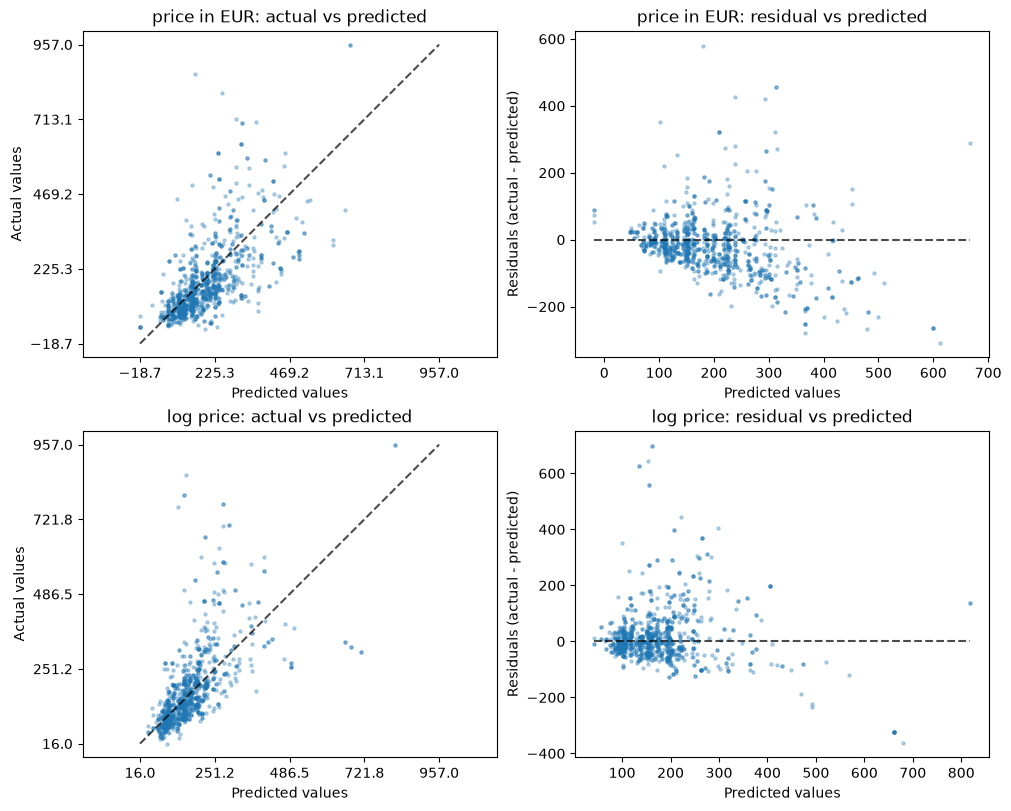

In [27]:
keep = (test["price"] < 1000).to_numpy()
fig, axs = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
for row, (name, m) in enumerate([("price in EUR", raw), ("log price", logged)]):
    p = m.predict(X_te)[keep]
    for col, kind in enumerate(["actual_vs_predicted", "residual_vs_predicted"]):
        PredictionErrorDisplay.from_predictions(test["price"].to_numpy()[keep], p, kind=kind,
                                                ax=axs[row, col], scatter_kwargs={"alpha": 0.3, "s": 5})
        axs[row, col].set_title(f"{name}: {kind.replace('_', ' ')}")
plt.show()

The model on euros predicts a negative price for three test listings and over-predicts most listings it prices above about €300: there the cloud of residuals sits below zero, a curved structure. The log model keeps all predictions positive, centres the bulk of its residuals on zero and has a lower MAE, median AE and MAPE. Its residuals still fan out for expensive listings. Statisticians often prefer to change the loss instead of the target, for example a Poisson or Tweedie regression with a log link (`PoissonRegressor`, `TweedieRegressor` in scikit-learn), which suits positive targets; that goes beyond this session.

> 📖 **Read more:** [extras/05-regression-metrics.ipynb](extras/05-regression-metrics.ipynb) (INRIA scikit-learn MOOC): the same metrics and plots on the Ames house prices, with a quantile transform of the target.

## Worked example · What drives nightly prices in Berlin?

The host's question, answered with the steps above: add one feature at a time, fit on the training listings, and report the test error in euros next to the baseline. A formula per model keeps the code short.

Next we loop over four formulas. For each, `.fit()` on `train`, `.predict(test)` on the test rows, and three metrics. The rows are collected in a list of dicts and turned into a DataFrame.

In [28]:
formulas = {
    "guests": "log_price ~ accommodates",
    "+ room type": "log_price ~ accommodates + C(room_type)",
    "+ distance": "log_price ~ accommodates + C(room_type) + km_to_centre",
    "+ district": "log_price ~ accommodates + C(room_type) + km_to_centre + C(district)",
}
results = [{"model": "baseline (median)", "MAE": baseline_mae}]
for name, formula in formulas.items():
    pred = np.exp(smf.ols(formula, data=train).fit().predict(test))
    results.append({"model": name, "MAE": mean_absolute_error(test["price"], pred),
                    "median AE": median_absolute_error(test["price"], pred),
                    "RMSE": root_mean_squared_error(test["price"], pred)})
pd.DataFrame(results).set_index("model").round(1)

,MAE,median AE,RMSE
model,,,
baseline (median),87.1,NaN,NaN
guests,68.8,42.1,119.2
+ room type,64.6,38.7,116.9
+ distance,62.9,38.0,116.1
+ district,62.3,36.6,115.5


Room type is the biggest step after the number of guests; distance and district add a little more. The full model misses a test listing by €62 on average, and half of the test listings are predicted within €37 (median absolute error). The RMSE hardly moves: no model of this kind can predict the few listings with prices in the thousands.

Next we look at the listings the full model misses most. `.nlargest(3, col)` and `.nsmallest(3, col)` return the rows with the three largest and smallest values.

In [29]:
full = smf.ols(formulas["+ district"], data=train).fit()
resid = test["log_price"] - full.predict(test)
cols = ["price", "room_type", "accommodates", "district", "number_of_reviews"]
worst = pd.concat([test.assign(resid=resid).nlargest(3, "resid"),
                   test.assign(resid=resid).nsmallest(3, "resid")])
worst[cols + ["resid"]].round(2)

,price,room_type,accommodates,district,number_of_reviews,resid
7617,1189.29,Entire home/apt,6,Treptow - Köpenick,0,2.03
8822,1000.00,Private room,4,Mitte,0,1.91
8152,759.57,Entire home/apt,1,Steglitz - Zehlendorf,0,1.73
80,9.03,Private room,2,Pankow,310,-2.42
9906,16.00,Private room,2,Friedrichshain-Kreuzberg,1,-1.84
148,29.07,Entire home/apt,2,Neukölln,0,-1.55


The largest residuals are asking prices far above anything comparable and rooms offered for under €20. Some may be errors, some genuine. Least squares feels all of them, which is why block 2 compares it with robust methods.

## Underfitting and overfitting

### Model complexity, underfitting and overfitting

**Model complexity** is how flexible a model is. A polynomial of degree d in x is a linear regression on the columns x, x², …, x^d: degree 1 is a straight line, degree 15 a curve with many bends. The model is still linear in its *parameters*, so least squares still fits it.

- **Underfitting**: the model is too rigid for the pattern, like describing a hilly road as flat. Training and test error are both high.
- **Overfitting**: the model follows the noise of the training rows, like a student who memorises past answers and fails on a new question. Training error is low, test error much higher.

![Polynomial fits of degree 1, 4 and 15 to 20 noisy points from a cosine curve, and training versus test error by degree](../figures/under-overfitting.png)

Training error always falls as complexity grows. Test error falls, reaches a minimum, and rises again. Only the test error tells you where to stop.

### Polynomial features by hand

*Adapted from [Non-linear feature engineering for linear regression](extras/06-polynomial-features.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

`PolynomialFeatures(degree=3, include_bias=False)` creates the columns x, x² and x³. `include_bias=False` drops the constant column, which would duplicate the intercept that `LinearRegression` adds anyway. The result is the same as stacking the powers by hand.

Next we check this on three distances. `np.concatenate([a, b, c], axis=1)` puts columns side by side; `.fit_transform` learns and applies the expansion in one call.

In [30]:
km = short[["km_to_centre"]].to_numpy()[:3]
by_hand = np.concatenate([km, km ** 2, km ** 3], axis=1)
by_sklearn = PolynomialFeatures(degree=3, include_bias=False).fit_transform(km)
print(by_sklearn.round(2))
print("largest difference:", np.abs(by_sklearn - by_hand).max())

[[1.56 2.45 3.83]
 [1.24 1.55 1.92]
 [1.72 2.95 5.06]]
largest difference: 8.881784197001252e-16


### Training and test error by degree

Next we reproduce the figure at the start of this section in numbers: 20 noisy training points from a cosine curve and 1,000 new points from the same curve. `make_pipeline(A, B)` chains the expansion with the regression so that one `fit` runs both (pipelines return in block 2).

**Predict before running:** which degree has the lowest training error, and which the lowest test error?

In [31]:
rng = np.random.default_rng(0)
x_tr = np.sort(rng.uniform(0, 1, 20)).reshape(-1, 1)
y_tr = np.cos(1.5 * np.pi * x_tr.ravel()) + rng.normal(0, 0.15, 20)
x_te = rng.uniform(0, 1, 1000).reshape(-1, 1)
y_te = np.cos(1.5 * np.pi * x_te.ravel()) + rng.normal(0, 0.15, 1000)
rows = []
for degree in [1, 2, 4, 8, 15]:
    poly = make_pipeline(PolynomialFeatures(degree), LinearRegression()).fit(x_tr, y_tr)
    rows.append({"degree": degree, "train RMSE": root_mean_squared_error(y_tr, poly.predict(x_tr)),
                 "test RMSE": root_mean_squared_error(y_te, poly.predict(x_te))})
pd.DataFrame(rows).set_index("degree").round(3)

,train RMSE,test RMSE
degree,,
1,0.449,0.459
2,0.220,0.257
4,0.084,0.169
8,0.069,0.329
15,0.061,0.650


Degree 1 underfits (both errors high), degree 4 is close to the truth, and from degree 8 on the training error keeps falling while the test error climbs.

### The gallery version with cross-validated error

*Code from [Underfitting vs. Overfitting](extras/07-underfitting-overfitting.ipynb) (scikit-learn gallery, BSD-3-Clause), unchanged except for the comments.*

The scikit-learn gallery draws the three classic panels and scores each degree with 10-fold **cross-validation**: the 30 points are split ten times into training and validation parts, and the validation MSE is averaged. Session 7 explains cross-validation; here it is enough that the number in each title is an honest test error.

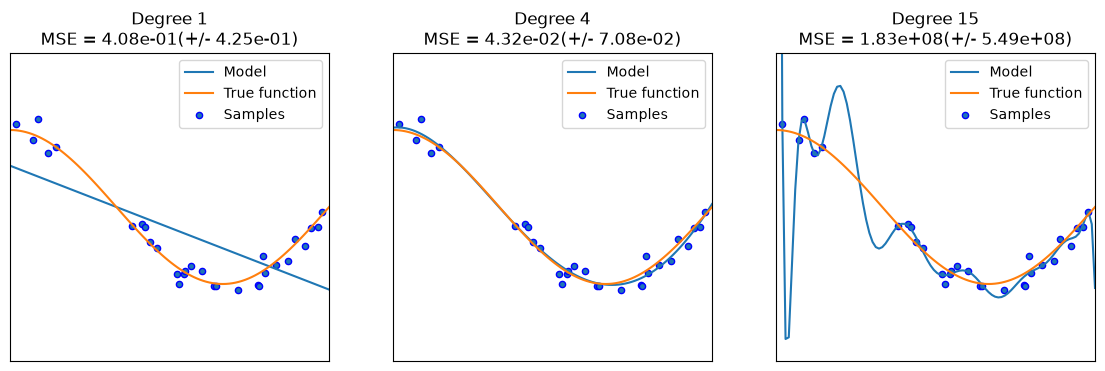

In [32]:
def true_fun(X):
    return np.cos(1.5 * np.pi * X)

np.random.seed(0)
n_samples, degrees = 30, [1, 4, 15]
X_g = np.sort(np.random.rand(n_samples))
y_g = true_fun(X_g) + np.random.randn(n_samples) * 0.1

plt.figure(figsize=(14, 4))
for i, degree in enumerate(degrees):
    ax = plt.subplot(1, len(degrees), i + 1)
    plt.setp(ax, xticks=(), yticks=())
    pipeline = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False),
                             LinearRegression(tol=np.finfo(float).eps))
    pipeline.fit(X_g[:, np.newaxis], y_g)
    scores = cross_val_score(pipeline, X_g[:, np.newaxis], y_g, scoring="neg_mean_squared_error", cv=10)
    X_plot = np.linspace(0, 1, 100)
    plt.plot(X_plot, pipeline.predict(X_plot[:, np.newaxis]), label="Model")
    plt.plot(X_plot, true_fun(X_plot), label="True function")
    plt.scatter(X_g, y_g, edgecolor="b", s=20, label="Samples")
    plt.xlim((0, 1)); plt.ylim((-2, 2)); plt.legend(loc="best")
    plt.title(f"Degree {degree}\nMSE = {-scores.mean():.2e}(+/- {scores.std():.2e})")
plt.show()

### Polynomial degree on the listings

Next, the same experiment on the listings: log price as a polynomial in guests and distance, fitted on all training listings. `StandardScaler()` first puts both features on the same scale so that high powers stay numerically manageable.

In [33]:
features = ["accommodates", "km_to_centre"]
rows = []
for degree in [1, 2, 3, 5, 8]:
    poly = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())
    poly.fit(train[features], train["log_price"])
    rows.append({"degree": degree,
                 "train RMSE": root_mean_squared_error(train["log_price"], poly.predict(train[features])),
                 "test RMSE": root_mean_squared_error(test["log_price"], poly.predict(test[features]))})
pd.DataFrame(rows).set_index("degree").round(3)

,train RMSE,test RMSE
degree,,
1,0.469,0.467
2,0.455,0.456
3,0.450,0.451
5,0.448,0.453
8,0.444,0.450


With over 4,000 training listings a little curvature helps (degree 2 or 3) and more hardly matters: training and test error stay close. Overfitting is a matter of **flexibility relative to the amount of data**. Exercise 1.7 asks what happens with far fewer listings.

### Other ways to add flexibility

*Adapted from [Non-linear feature engineering for linear regression](extras/06-polynomial-features.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

A polynomial is not the only way to let a linear model bend. Three alternatives:

- **binning** (`KBinsDiscretizer`): cut the feature into intervals and fit one level per interval, a staircase;
- **splines** (`SplineTransformer`): join smooth cubic pieces at knots; they bend locally and do not shoot off at the edges like high-degree polynomials;
- a model that is non-linear by nature, such as a **decision tree** (Session 10).

Next we fit each to log price on distance alone and draw the four curves. All are pipelines or estimators with the same `fit` and `predict`.

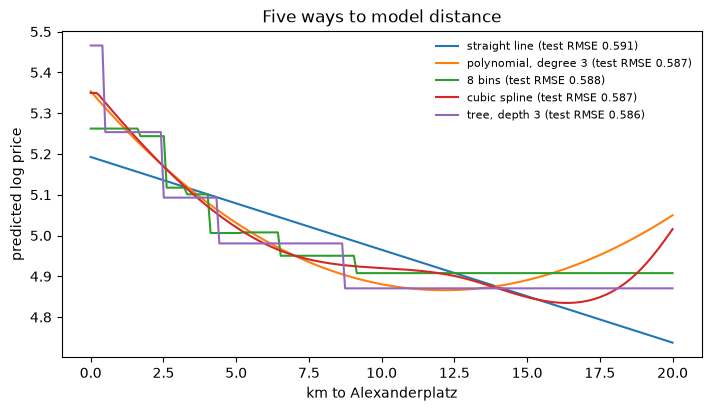

In [34]:
flex = {"straight line": LinearRegression(),
        "polynomial, degree 3": make_pipeline(PolynomialFeatures(3), LinearRegression()),
        "8 bins": make_pipeline(KBinsDiscretizer(n_bins=8, quantile_method="averaged_inverted_cdf"), LinearRegression()),
        "cubic spline": make_pipeline(SplineTransformer(degree=3, n_knots=5), LinearRegression()),
        "tree, depth 3": DecisionTreeRegressor(max_depth=3, random_state=0)}
grid_km = pd.DataFrame({"km_to_centre": np.linspace(0, 20, 200)})
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for name, m in flex.items():
    m.fit(train[["km_to_centre"]], train["log_price"])
    rmse = root_mean_squared_error(test["log_price"], m.predict(test[["km_to_centre"]]))
    ax.plot(grid_km["km_to_centre"], m.predict(grid_km), label=f"{name} (test RMSE {rmse:.3f})")
ax.set(xlabel="km to Alexanderplatz", ylabel="predicted log price", title="Five ways to model distance")
ax.legend(frameon=False, fontsize=8)
plt.show()

The flexible versions agree that prices fall fastest in the first few kilometres and flatten from about 9 km; the straight line misses that shape. The polynomial and the spline bend up again at the far edge, where there are few listings, and the tree has a spike right at the centre: flexibility follows the data where data are thin. All five test RMSEs lie within 0.01 of each other, because distance alone explains little of the price.

### The bias–variance trade-off

The **bias–variance trade-off** is the official name for the tension between two sources of test error. Imagine fitting the same model to many different training samples. **Bias** is how far the average of all those fits is from the truth: a straight line through a curve misses it the same way every time. **Variance** is how much the fits differ from each other: a degree-15 polynomial changes wildly with each new sample. Think of darts: bias is aiming at the wrong spot, variance is a shaky hand. The expected squared test error is bias² + variance + noise, where noise is the part no model can predict. More complexity lowers bias and raises variance; more data lowers variance.

Next we measure both on the toy curve: 200 training samples of 20 points each, one fit per sample, then bias² and variance of the predictions on a grid. `np.array(list_of_arrays)` stacks the predictions into a 200 × 50 table; `.mean(axis=0)` and `.var(axis=0)` work per grid point.

In [35]:
rng = np.random.default_rng(1)
grid = np.linspace(0.05, 0.95, 50).reshape(-1, 1)
truth = np.cos(1.5 * np.pi * grid.ravel())
for degree in [1, 4, 12]:
    preds = []
    for _ in range(200):
        xs = rng.uniform(0, 1, 20).reshape(-1, 1)
        ys = np.cos(1.5 * np.pi * xs.ravel()) + rng.normal(0, 0.15, 20)
        preds.append(make_pipeline(PolynomialFeatures(degree), LinearRegression()).fit(xs, ys).predict(grid))
    preds = np.array(preds)
    print(f"degree {degree:2d}  bias^2 {np.mean((preds.mean(axis=0) - truth) ** 2):.3f}"
          f"  variance {preds.var(axis=0).mean():.3f}")

degree  1  bias^2 0.145  variance 0.029
degree  4  bias^2 0.000  variance 0.008
degree 12  bias^2 0.013  variance 7.851


The straight line has high bias and low variance, degree 12 the opposite, degree 4 is low on both. The remedies differ:

```mermaid
flowchart TD
    A["compare training and test error"] --> B{"training error high?"}
    B -->|"yes"| U["underfitting:<br/>more features, a more flexible model"]
    B -->|"no"| C{"test error much higher?"}
    C -->|"yes"| O["overfitting:<br/>simpler model, more data,<br/>regularisation (Session 7)"]
    C -->|"no"| G["good fit"]
```

> **Note.** The decomposition into bias² + variance + noise is exact for squared error. For other losses the idea carries over, but the formula differs.

> 📖 **Read more:** [extras/06-polynomial-features.ipynb](extras/06-polynomial-features.ipynb) (INRIA scikit-learn MOOC): polynomial, binned, spline, kernel (SVR) and Nystroem features on a cubic toy problem.
>
> 📖 **Read more:** [extras/07-underfitting-overfitting.ipynb](extras/07-underfitting-overfitting.ipynb) (scikit-learn gallery): the original example of the three panels.

## Check your understanding

1. At which lifecycle stage are the target, the metric and the baseline fixed, and what are they for the price model?
2. Why is the error on the training rows an optimistic estimate of the error on new listings?
3. The coefficient of a private room is −0.389 on the log scale. What does it compare, and what is it in per cent?
4. The full price model has MAE €62 and RMSE €116 on the test listings. What does the gap say about the errors?
5. A model has training RMSE 0.06 and test RMSE 0.65. Underfitting or overfitting? Name two remedies.

## Exercises (30 min)

Work in pairs; one types, the other directs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. The code exercises reuse `short`, `train` and `test` from above, so run the notebook first.

### 1.1 · A pricing aid along the lifecycle

*Pairs · 10 min*

> What would it take to turn a Berlin price model into a pricing aid for hosts? For each stage of the lifecycle, write one sentence on what it means for this task and which session covers it. Think about what is known when a host lists a *new* flat.

*Source:* original exercise for this course

*Your answer:*

| Stage | What it means for the price model | Session |
|---|---|---|
| 01 Problem definition | | |
| 02 Data collection | | |
| 03 Cleaning | | |
| 04 Exploratory analysis | | |
| 05 Features | | |
| 06 Model selection | | |
| 07 Training | | |
| 08 Evaluation and tuning | | |
| 09 Deployment | | |
| 10 Monitoring | | |

### 1.2 · Fit a line by hand

*Paper · 10 min*

> Find the least-squares line for the points (1, 1), (2, 2), (3, 2).

*Source:* [Simple linear regression, Wikipedia](https://en.wikipedia.org/wiki/Simple_linear_regression)

*Your answer:*

### 1.3 · The coefficient of log price

*Paper · 5 min*

> A coefficient of +0.1 in a model of `log(price)` means what for the price?

*Source:* [UCLA OARC: interpreting models with log-transformed variables](https://stats.oarc.ucla.edu/other/mult-pkg/faq/general/faqhow-do-i-interpret-a-regression-model-when-some-variables-are-log-transformed/)

*Your answer:*

### 1.4 · The dummy variable trap

*Predict · 5 min*

> You put all four room-type dummies (entire home, hotel room, private room, shared room) into a linear regression together with an intercept. What happens?

*Source:* [Dummy variable (statistics), Wikipedia](https://en.wikipedia.org/wiki/Dummy_variable_(statistics))

*Your answer:*

### 1.5 · Ten points, a polynomial of degree 9

*Predict · 5 min*

> You fit a polynomial of degree 9 to ten training points. What is the training R²? What will the test R² look like?

*Source:* [Bishop, *Pattern Recognition and Machine Learning* (2006), §1.1, free PDF](https://www.microsoft.com/en-us/research/uploads/prod/2006/01/Bishop-Pattern-Recognition-and-Machine-Learning-2006.pdf)

*Your answer:*

### 1.6 · A price model for private rooms

*Code · 15 min*

> Restrict `short` to private rooms. Split them 80/20 with `train_test_split(..., random_state=42)`, fit a linear regression of the log price on the number of guests, the distance to the centre and the district, and report the test MAE in euros against the median-price baseline of the training rooms. Interpret the coefficient of `accommodates` as a percentage. What does a separate model for private rooms allow that one model for all room types with a private-room dummy does not?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

### 1.7 · How much data does a flexible model need?

*Code · 10 min*

*Stretch:*

> Repeat the polynomial experiment on the listings (section "Underfitting and overfitting") (guests and distance, degrees 1, 2, 3, 5, 8), but fit on only 60 training listings (`train.sample(60, random_state=0)`) and score on the full test set. At which degree does the test error start to rise, and where does it explode? Then try 500 training listings. What does this say about flexibility relative to the amount of data?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

## Debrief (15 min)

- **Compare** two lifecycle tables (1.1) and two private-room models (1.6). Did both pairs beat the baseline, and by how much in euros?
- **Look for** features a new host would not have (reviews, `estimated_revenue_l365d`), an error reported on the log scale instead of in euros, and a test set used more than once to choose the model.
- **Typical mistake:** reading a log-scale coefficient as euros (1.3), or reading a coefficient as "adding a guest raises the price by …" (a causal claim the data do not support).
- **Bridge to block 2:** the largest residuals were extreme asking prices, and least squares feels them fully. Block 2 changes the loss (robust and quantile regression) and then the target (yes/no outcomes with logistic regression).

## Further reading

- James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, chapters 2 (section 2.2, the bias–variance trade-off) and 3 (linear regression), with Lab 3. Springer. <https://www.statlearning.com/>
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow*, 3rd ed., chapter 4 (linear and polynomial regression). O'Reilly.
- INRIA (2024). *scikit-learn MOOC*, modules "The predictive modeling pipeline" and "Linear models" (CC BY 4.0). <https://inria.github.io/scikit-learn-mooc/>
- scikit-learn developers. *Common pitfalls in the interpretation of coefficients of linear models* and *Underfitting vs. Overfitting* (gallery examples, BSD-3-Clause). <https://scikit-learn.org/stable/auto_examples/>
- Chapman, P. et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS.
- Sculley, D. et al. (2015). Hidden technical debt in machine learning systems. *NeurIPS 28*. <https://papers.nips.cc/paper/5656-hidden-technical-debt-in-machine-learning-systems>
- Data: Inside Airbnb, Berlin, snapshot of 26 June 2026 (CC BY 4.0). <https://insideairbnb.com/get-the-data/>
- Extras of this block: [01](extras/01-linear-regression-without-sklearn.ipynb), [02](extras/02-linear-regression-in-sklearn.ipynb), [03](extras/03-islp-linear-regression-lab.ipynb), [04](extras/04-coefficient-interpretation-pitfalls.ipynb), [05](extras/05-regression-metrics.ipynb), [06](extras/06-polynomial-features.ipynb), [07](extras/07-underfitting-overfitting.ipynb); provenance and licences in [extras/README.md](extras/README.md).